In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
import pandas as pd
from src.data_loader import load_heart
from src.preprocessing import build_preprocessor, split_data

X, y = load_heart()
X_train, X_test, y_train, y_test = split_data(X, y)

prep = build_preprocessor(X_train, "heart")
Xt = prep.fit_transform(X_train)          # fit on training data only
Xt = pd.DataFrame(Xt, columns=prep.get_feature_names_out())

print("Before:", X_train.shape, "| missing:", int(X_train.isna().sum().sum()))
print("After: ", Xt.shape, "| missing:", int(Xt.isna().sum().sum()))
display(Xt.head())

Before: (242, 13) | missing: 2
After:  (242, 25) | missing: 0


,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,num__ca,cat__sex_0.0,cat__sex_1.0,cat__cp_1.0,cat__cp_2.0,...,cat__restecg_1.0,cat__restecg_2.0,cat__exang_0.0,cat__exang_1.0,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0
0,-0.729485,-0.395692,0.458139,0.708371,-0.445445,-0.689715,0.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.050166,-0.054513,0.230598,0.222495,-0.891627,-0.689715,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.061212,0.059213,0.723605,0.399178,-0.891627,0.445734,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.061212,-1.305501,1.121803,0.266666,-0.891627,-0.689715,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.272924,0.514117,-0.167601,-1.190962,-0.713154,-0.689715,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.data_loader import load_all, FIGURES_DIR
from src.preprocessing import build_preprocessor, split_data

sns.set_theme(style="whitegrid")
datasets = load_all()

In [3]:
rows = []
for name, (X, y) in datasets.items():
    X_tr, X_te, y_tr, y_te = split_data(X, y)
    rows.append({"dataset": name, "train": len(X_tr), "test": len(X_te),
                 "positive % (train)": round(y_tr.mean() * 100, 1),
                 "positive % (test)": round(y_te.mean() * 100, 1)})
display(pd.DataFrame(rows))

,dataset,train,test,positive % (train),positive % (test)
0,heart,242,61,45.9,45.9
1,breast,455,114,37.4,36.8
2,diabetes,614,154,34.9,35.1


In [4]:
summary = []
for name, (X, y) in datasets.items():
    X_tr, X_te, y_tr, y_te = split_data(X, y)
    prep = build_preprocessor(X_tr, name)
    Xt = pd.DataFrame(prep.fit_transform(X_tr), columns=prep.get_feature_names_out())
    summary.append({"dataset": name,
                    "columns before": X_tr.shape[1], "columns after": Xt.shape[1],
                    "missing before": int(X_tr.isna().sum().sum()),
                    "missing after": int(Xt.isna().sum().sum())})
display(pd.DataFrame(summary))

,dataset,columns before,columns after,missing before,missing after
0,heart,13,25,2,0
1,breast,30,30,0,0
2,diabetes,8,8,501,0


In [5]:
X, y = datasets["heart"]
X_tr, X_te, y_tr, y_te = split_data(X, y)
prep = build_preprocessor(X_tr, "heart")
Xt = pd.DataFrame(prep.fit_transform(X_tr), columns=prep.get_feature_names_out())
display(Xt.head())
print("Missing values after:", int(Xt.isna().sum().sum()))

,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,num__ca,cat__sex_0.0,cat__sex_1.0,cat__cp_1.0,cat__cp_2.0,...,cat__restecg_1.0,cat__restecg_2.0,cat__exang_0.0,cat__exang_1.0,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0
0,-0.729485,-0.395692,0.458139,0.708371,-0.445445,-0.689715,0.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.050166,-0.054513,0.230598,0.222495,-0.891627,-0.689715,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.061212,0.059213,0.723605,0.399178,-0.891627,0.445734,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.061212,-1.305501,1.121803,0.266666,-0.891627,-0.689715,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.272924,0.514117,-0.167601,-1.190962,-0.713154,-0.689715,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


Missing values after: 0


Insulin                     48.7
SkinThickness               29.6
BloodPressure                4.6
BMI                          1.4
Glucose                      0.7
Pregnancies                  0.0
DiabetesPedigreeFunction     0.0
Age                          0.0
dtype: float64


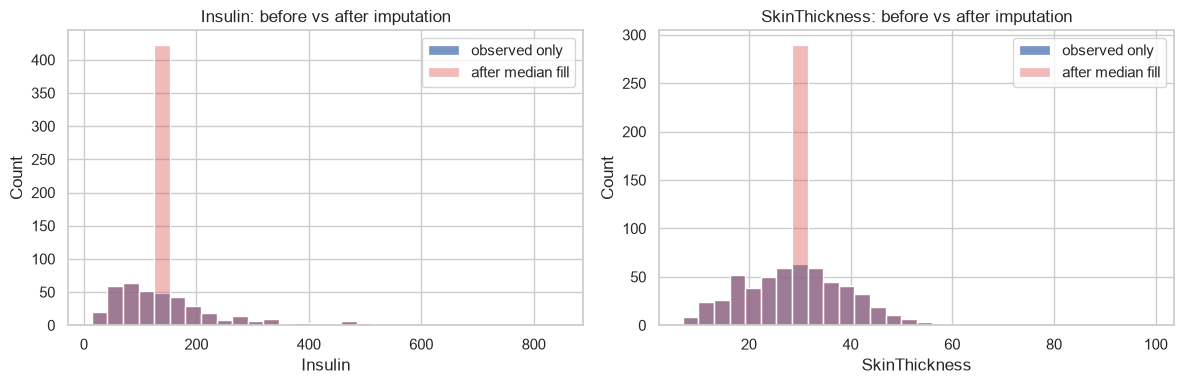

In [6]:
X, y = datasets["diabetes"]
print((X.isna().mean() * 100).round(1).sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Insulin", "SkinThickness"]):
    filled = X[col].fillna(X[col].median())
    sns.histplot(X[col].dropna(), bins=30, color="#4C72B0", label="observed only", ax=ax)
    sns.histplot(filled, bins=30, color="#D9534F", alpha=0.4, label="after median fill", ax=ax)
    ax.set_title(f"{col}: before vs after imputation")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "diabetes_imputation.png", dpi=150)
plt.show()

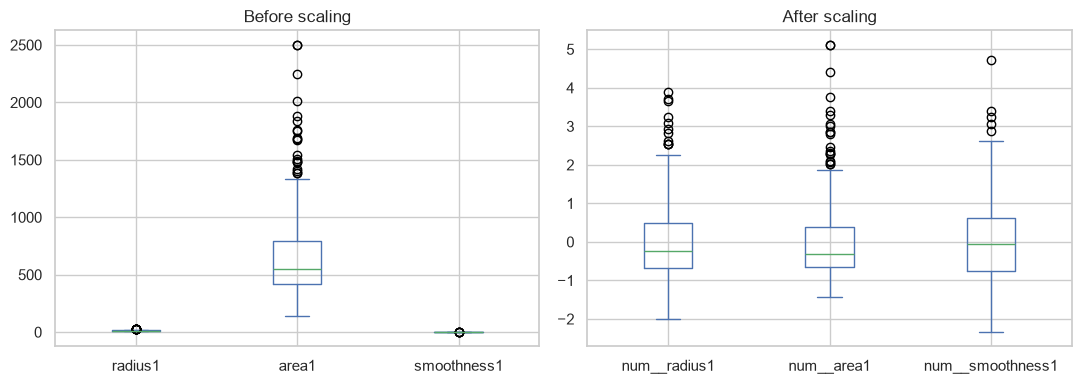

In [7]:
X, y = datasets["breast"]
X_tr, X_te, y_tr, y_te = split_data(X, y)
prep = build_preprocessor(X_tr, "breast")
Xt = pd.DataFrame(prep.fit_transform(X_tr), columns=prep.get_feature_names_out())

cols = ["radius1", "area1", "smoothness1"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
X_tr[cols].plot(kind="box", ax=axes[0], title="Before scaling")
Xt[[f"num__{c}" for c in cols]].plot(kind="box", ax=axes[1], title="After scaling")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scaling_effect.png", dpi=150)
plt.show()